# PQ-ZKAuth — Phase 2
**BCSE328L Cryptocurrency Technologies** · PQC authentication, zero-knowledge authorization, and a lightweight blockchain.

## 1. Project Overview
PQ-ZKAuth accepts a transaction only when its ML-DSA signature and its zero-knowledge authorization proof both verify.

## 2. Problem Statement
Ordinary blockchain authentication can reveal more identity or authorization information than a verifier needs.

## 3. Research Motivation
ML-DSA provides a NIST-standardized post-quantum signature scheme. A Schnorr proof lets an authorized user prove credential knowledge without transmitting the credential.

## 4. Environment & Dependencies
This notebook was executed with Python 3.14. `pqcrypto` supplies ML-DSA-44; `ecdsa` supplies audited secp256k1 group arithmetic; Pandas and Matplotlib report measured results.

In [1]:
import os
from copy import deepcopy
import matplotlib.pyplot as plt
import pandas as pd
from pqcrypto.sign import ml_dsa_44
from pq_zkauth import *
print('ML-DSA algorithm:', ml_dsa_44.ALGORITHM)
print('ML-DSA public key bytes:', ml_dsa_44.PUBLIC_KEY_SIZE)
print('ML-DSA signature bytes:', ml_dsa_44.SIGNATURE_SIZE)

ML-DSA algorithm: Mldsa44
ML-DSA public key bytes: 1312
ML-DSA signature bytes: 2420


## 5. Configuration
Transactions use canonical sorted JSON. The authorization proof domain-separates and hashes the transaction into its Fiat–Shamir challenge.

In [2]:
alice = PQCIdentity.generate('alice')
bob = PQCIdentity.generate('bob')
validator = PQZKValidator(
    public_keys={'alice': alice.public_key, 'bob': bob.public_key},
    authorized_credentials={'alice': alice.credential_commitment},
)
chain = Blockchain()
print('Alice and Bob have independent ML-DSA identities.')
print('Only Alice’s public credential commitment is registered for authorization.')

Alice and Bob have independent ML-DSA identities.
Only Alice’s public credential commitment is registered for authorization.


## 6. PQC Identity Generation
`PQCIdentity` keeps private ML-DSA material and the credential witness local. Neither is printed or serialized into transactions.

In [3]:
print({'alice_id': alice.user_id, 'public_key_bytes': len(alice.public_key), 'credential_secret_transmitted': False})

{'alice_id': 'alice', 'public_key_bytes': 1312, 'credential_secret_transmitted': False}


## 7. PQC Transaction Signing
The sender, receiver, amount, timestamp, nonce, and transaction ID are deterministically serialized before ML-DSA signing.

In [4]:
alice_tx = create_signed_transaction(alice, 'merchant', 10, 'alice-transfer-001')
print('Signature generated:', alice_tx.signature is not None)
print('Canonical payload:', alice_tx.signing_bytes().decode())

Signature generated: True
Canonical payload: {"amount":10,"nonce":"833604fb3fc596c8bd17a0e8","receiver":"merchant","sender":"alice","timestamp":"2026-10-07T19:11:41.254513+00:00","transaction_id":"alice-transfer-001"}


## 8. PQC Signature Verification
The original signed payload verifies. Any change to a signed field causes verification failure.

In [5]:
print('Original signature valid:', verify_signature(alice_tx, alice.public_key))
changed = clone_transaction(alice_tx); changed.amount = 100
print('Modified amount signature valid:', verify_signature(changed, alice.public_key))

Original signature valid: True
Modified amount signature valid: False


## 9. ZKP Authorization
This is a genuine non-interactive Schnorr proof of knowledge on secp256k1: the response verifies `sG = R + cP`. The private credential remains only inside `PQCIdentity`; the transaction carries only public proof values.

In [6]:
print('Private credential: NOT REVEALED')
print('Proof generated:', alice_tx.zk_proof is not None)
print('Verifier valid:', verify_zk_proof(alice_tx, alice.credential_commitment))

Private credential: NOT REVEALED
Proof generated: True
Verifier valid: True


## 10. Blockchain Implementation
Blocks are SHA-256-linked records. This integrity hash is separate from PQC authentication and no proof-of-work or networking is used.

## 11. PQ-ZKAuth Validator
The validator returns structured outcomes and accepts only valid basic fields, ML-DSA authentication, and registered-credential proof verification.

In [7]:
accepted = validator.validate_transaction(alice_tx)
accepted.as_dict()

{'pqc_valid': True,
 'zkp_valid': True,
 'transaction_valid': True,
 'accepted': True,
 'reason': 'Authentication and authorization successful'}

## 12. Successful Transaction Demonstration
Alice’s valid transaction is accepted, then committed to a new lightweight block.

In [8]:
if accepted.accepted:
    block = chain.add_block([alice_tx])
print({'accepted': accepted.accepted, 'block_index': block.index, 'block_hash': block.hash, 'chain_valid': chain.validate_chain()})

{'accepted': True, 'block_index': 1, 'block_hash': '58e770e4ae68c531d9f9ae3260dea492e3d6a94001e25d2042806fdf80eb29bf', 'chain_valid': True}


## 13. Attack Simulation 1 — Tampering
Changing amount 10 to 100 after signing changes the canonical payload, invalidating ML-DSA. The proof is also transaction-bound, so it fails too.

In [9]:
tampered = clone_transaction(alice_tx); tampered.amount = 100
tampered_result = validator.validate_transaction(tampered)
tampered_result.as_dict()

{'pqc_valid': False,
 'zkp_valid': False,
 'transaction_valid': True,
 'accepted': False,
 'reason': 'ML-DSA signature invalid'}

## 14. Attack Simulation 2 — Forged Identity
Mallory signs a payload claiming to be Alice. The validator selects Alice’s registered public key, so Mallory’s signature fails.

In [10]:
mallory = PQCIdentity.generate('mallory')
forged = clone_transaction(alice_tx)
mallory.sign_transaction(forged)
forged_result = validator.validate_transaction(forged)
forged_result.as_dict()

{'pqc_valid': False,
 'zkp_valid': True,
 'transaction_valid': True,
 'accepted': False,
 'reason': 'ML-DSA signature invalid'}

## 15. Attack Simulation 3 — Invalid Authorization
Bob has a legitimate ML-DSA identity and signs correctly, but his credential commitment is not authorized. Authentication passes while authorization rejects.

In [11]:
bob_tx = create_signed_transaction(bob, 'merchant', 10, 'bob-transfer-001')
bob_result = validator.validate_transaction(bob_tx)
bob_result.as_dict()

{'pqc_valid': True,
 'zkp_valid': False,
 'transaction_valid': True,
 'accepted': False,
 'reason': 'Authorization proof invalid'}

## 16. Blockchain Integrity Validation
Every stored block’s SHA-256 hash and predecessor link are rechecked.

In [12]:
print('Blockchain integrity =', 'VALID' if chain.validate_chain() else 'INVALID')

Blockchain integrity = VALID


## 17. Performance Benchmarking
Twenty actual trials are measured with `perf_counter_ns`; results are not fabricated. Times are milliseconds.

In [13]:
summary, measurements = benchmark(trials=20)
summary_table = pd.DataFrame(summary).T[['mean', 'median', 'std', 'min', 'max']]
summary_table.round(3)

,mean,median,std,min,max
PQC key generation,0.101,0.099,0.006,0.096,0.114
PQC signing,4.944,4.911,0.124,4.892,5.466
PQC verification,0.103,0.099,0.018,0.097,0.180
ZKP generation,0.721,0.706,0.046,0.678,0.857
ZKP verification,1.701,1.652,0.126,1.599,2.089
Transaction validation,1.459,1.440,0.090,1.369,1.819
Block creation,0.038,0.035,0.012,0.025,0.060
End-to-end,7.225,7.166,0.184,7.060,7.898


## 18. Results Visualization
The following plots use the actual benchmark dataframe and are saved under `figures/`.

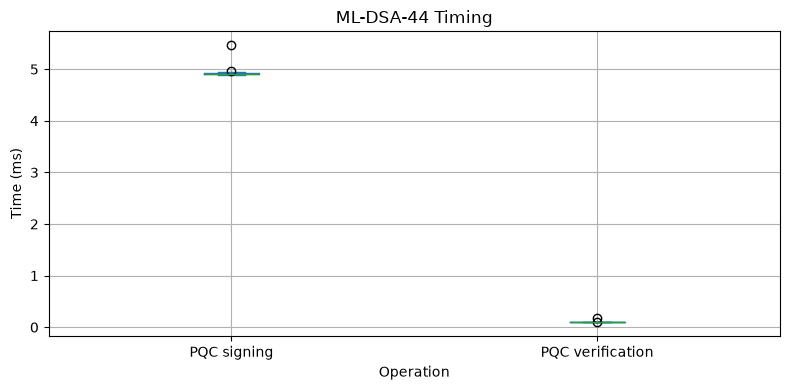

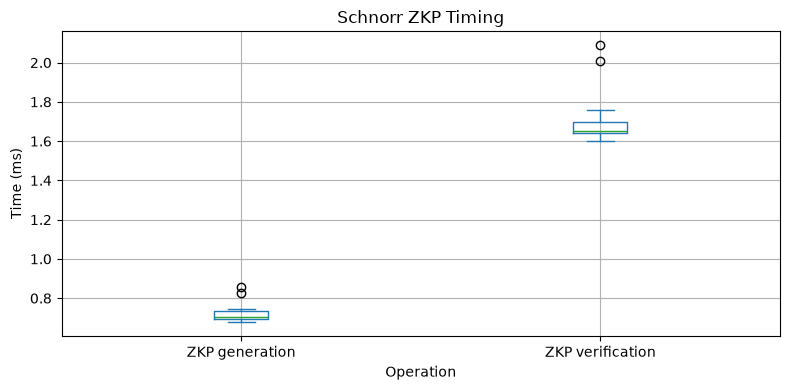

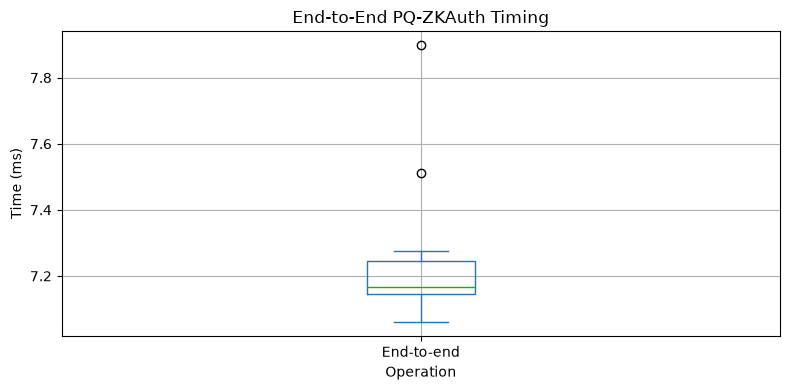

In [14]:
os.makedirs('figures', exist_ok=True)
def timing_plot(columns, title, filename):
    ax = measurements[columns].plot(kind='box', figsize=(8, 4), grid=True)
    ax.set_title(title); ax.set_ylabel('Time (ms)'); ax.set_xlabel('Operation')
    plt.tight_layout(); plt.savefig(os.path.join('figures', filename), dpi=180); plt.show()
timing_plot(['PQC signing', 'PQC verification'], 'ML-DSA-44 Timing', 'pqc_signing_vs_verification.png')
timing_plot(['ZKP generation', 'ZKP verification'], 'Schnorr ZKP Timing', 'zkp_generation_vs_verification.png')
timing_plot(['End-to-end'], 'End-to-End PQ-ZKAuth Timing', 'end_to_end_validation.png')

## 19. Security Discussion
ML-DSA protects signed transaction fields against alteration and forgery. The proof establishes credential knowledge without sending its scalar secret. This does not make the blockchain anonymous: sender IDs, amounts, and public commitments remain visible in this prototype.

## 20. Limitations
This is a local educational prototype: it has no distributed consensus, revocation, persistent secure key storage, network adversary model, or production privacy layer. The Schnorr proof uses classical secp256k1; only the signature primitive is post-quantum.

## 21. Phase 2 Summary
The acceptance rule was demonstrated: valid ML-DSA **and** valid ZKP accepts Alice; transaction tampering, forged signatures, and valid-but-unauthorized Bob all reject.

# Phase 3 — Experimental Evaluation & Research Validation
All numerical outputs in this section are generated by the cells below on the local CPU. No result values are hard-coded.

## 1. Existing Implementation
Phase 2 is retained unchanged: ML-DSA-44 authenticates canonical transaction payloads and a transaction-bound Schnorr Fiat–Shamir proof demonstrates knowledge of an authorization credential.

## 2. Experimental Methodology
Independent PQC, ZKP, and end-to-end benchmarks use 100 trials. Timings use `perf_counter_ns`; reported 95% intervals are normal-approximation intervals for this local prototype, not claims of broad statistical significance.

In [15]:
from pathlib import Path
TRIALS = 100
RESULTS_DIR = Path('results'); RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR = Path('figures'); FIGURES_DIR.mkdir(exist_ok=True)
environment = environment_details(TRIALS)
pd.DataFrame([environment]).to_csv(RESULTS_DIR / 'environment.csv', index=False)
pd.DataFrame([environment]).T.rename(columns={0: 'value'})

,value
python,3.14.7
platform,Windows-11-10.0.26200-SP0
processor,"AMD64 Family 25 Model 117 Stepping 2, Authenti..."
cpu_count,16
pqcrypto,1.0.0
ecdsa,0.19.2
pandas,3.0.6
matplotlib,3.11.1
trial_count,100
gpu_used,False


## 3. Environment and Reproducibility
The environment table is saved as `results/environment.csv`. This CPU-oriented workload intentionally does not use a GPU.

## 4. PQC Benchmark
ML-DSA-44 key generation, signing, and verification are benchmarked independently. Raw trials include public-key, private-key, and signature sizes.

In [16]:
pqc_raw = benchmark_pqc(TRIALS)
pqc_raw.to_csv(RESULTS_DIR / 'pqc_benchmark.csv', index=False)
pqc_summary = summarize_measurements(pqc_raw[['key_generation_ms', 'signing_ms', 'verification_ms']])
pqc_summary.to_csv(RESULTS_DIR / 'pqc_summary.csv', index=False)
display(pqc_summary.round(4))
display(pqc_raw[['public_key_bytes', 'private_key_bytes', 'signature_bytes']].iloc[:1])

,metric,mean_ms,median_ms,std_ms,min_ms,max_ms,ci95_half_width_ms,trials
0,key_generation_ms,0.0958,0.0934,0.0103,0.0910,0.1705,0.0020,100
1,signing_ms,4.9401,4.9088,0.1222,4.8839,5.8544,0.0240,100
2,verification_ms,0.0901,0.0882,0.0089,0.0870,0.1708,0.0017,100


,public_key_bytes,private_key_bytes,signature_bytes
0,1312,2560,2420


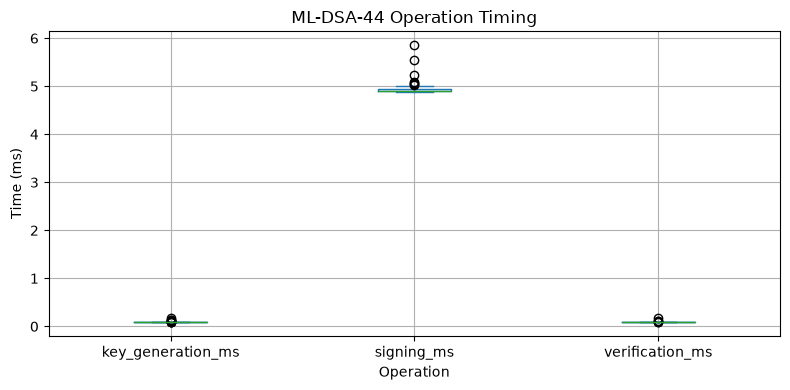

In [17]:
ax = pqc_raw[['key_generation_ms', 'signing_ms', 'verification_ms']].plot(kind='box', figsize=(8, 4), grid=True)
ax.set(title='ML-DSA-44 Operation Timing', xlabel='Operation', ylabel='Time (ms)')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'phase3_pqc_timing.png', dpi=180); plt.show()

## 5. ZKP Benchmark
The proof benchmark measures actual Schnorr proof generation and verification. `proof_bytes` is the canonical JSON serialization size of the public proof object.

In [18]:
zkp_raw = benchmark_zkp(TRIALS)
zkp_raw.to_csv(RESULTS_DIR / 'zkp_benchmark.csv', index=False)
zkp_summary = summarize_measurements(zkp_raw[['proof_generation_ms', 'proof_verification_ms']])
zkp_summary.to_csv(RESULTS_DIR / 'zkp_summary.csv', index=False)
display(zkp_summary.round(4)); display(zkp_raw[['proof_bytes']].iloc[:1])

,metric,mean_ms,median_ms,std_ms,min_ms,max_ms,ci95_half_width_ms,trials
0,proof_generation_ms,0.7250,0.7036,0.0826,0.6371,1.1178,0.0162,100
1,proof_verification_ms,1.7477,1.7136,0.1350,1.6353,2.6395,0.0265,100


,proof_bytes
0,223


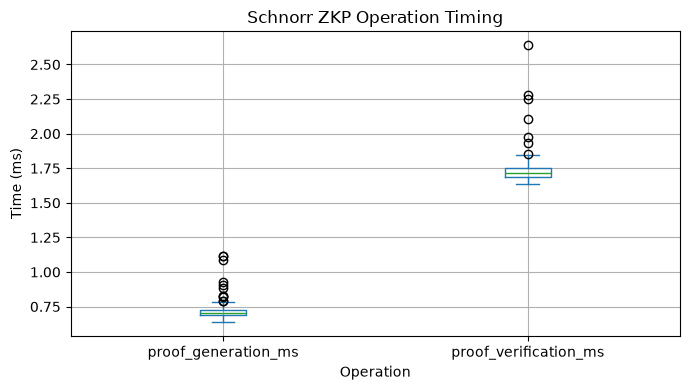

In [19]:
ax = zkp_raw[['proof_generation_ms', 'proof_verification_ms']].plot(kind='box', figsize=(7, 4), grid=True)
ax.set(title='Schnorr ZKP Operation Timing', xlabel='Operation', ylabel='Time (ms)')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'phase3_zkp_timing.png', dpi=180); plt.show()

## 6. End-to-End Benchmark
The proposed configuration measures signing, proof generation, independent checks, validator execution, block insertion plus chain validation, and total latency.

In [20]:
e2e_raw = benchmark_end_to_end(TRIALS)
e2e_raw.to_csv(RESULTS_DIR / 'end_to_end_benchmark.csv', index=False)
e2e_summary = summarize_measurements(e2e_raw.drop(columns='trial'))
e2e_summary.to_csv(RESULTS_DIR / 'end_to_end_summary.csv', index=False)
display(e2e_summary.round(4))

,metric,mean_ms,median_ms,std_ms,min_ms,max_ms,ci95_half_width_ms,trials
0,pqc_signing_ms,5.0781,4.9580,0.5040,4.9046,7.8638,0.0988,100
1,zkp_generation_ms,0.7209,0.7078,0.0524,0.6526,0.9220,0.0103,100
2,pqc_verification_ms,0.1026,0.0991,0.0113,0.0966,0.1819,0.0022,100
3,zkp_verification_ms,1.7331,1.6929,0.1488,1.6299,2.3747,0.0292,100
4,validator_ms,1.4814,1.4520,0.1342,1.3748,2.0562,0.0263,100
5,blockchain_ms,0.0517,0.0497,0.0091,0.0397,0.0765,0.0018,100
6,end_to_end_ms,7.3321,7.1647,0.6531,7.0468,10.8958,0.1280,100


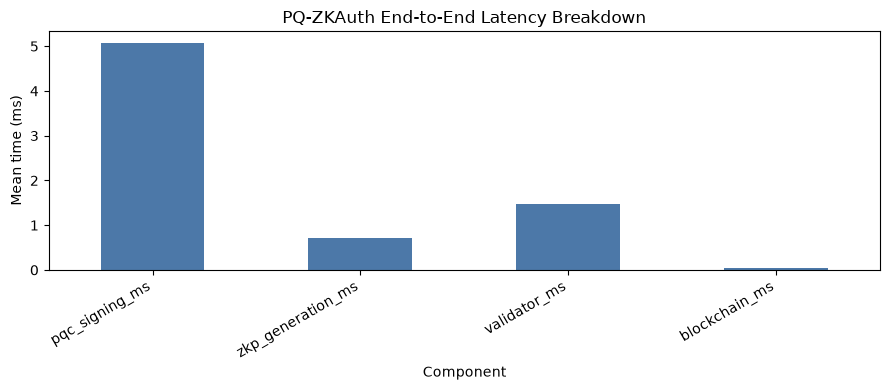

In [21]:
breakdown = e2e_raw[['pqc_signing_ms', 'zkp_generation_ms', 'validator_ms', 'blockchain_ms']].mean().rename('mean_ms')
ax = breakdown.plot(kind='bar', figsize=(9, 4), color='#4C78A8')
ax.set(title='PQ-ZKAuth End-to-End Latency Breakdown', xlabel='Component', ylabel='Mean time (ms)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.savefig(FIGURES_DIR / 'phase3_end_to_end_breakdown.png', dpi=180); plt.show()

## 7. Baseline Comparison and 8. Ablation Study
The conventional baseline is ECDSA/secp256k1 with SHA-256: it authenticates but has neither PQC authentication nor privacy-preserving authorization. PQC-only uses ML-DSA without a proof. The proposed configuration uses both. This is a functional comparison, not a claim of equal cryptographic security levels.

In [22]:
comparison_raw = compare_configurations(TRIALS)
comparison_raw.to_csv(RESULTS_DIR / 'baseline_comparison.csv', index=False)
comparison_summary = comparison_raw.groupby('configuration')[['authentication_ms', 'verification_ms', 'end_to_end_ms', 'communication_bytes']].agg(['mean', 'median', 'std', 'min', 'max'])
comparison_summary.to_csv(RESULTS_DIR / 'baseline_comparison_summary.csv')
ablation = comparison_raw.groupby('configuration', as_index=False)[['authentication_ms', 'verification_ms', 'end_to_end_ms', 'communication_bytes']].mean()
ablation['Authentication'] = 'Yes'
ablation['Privacy Authorization'] = ablation.configuration.eq('PQC + ZKP').map({True: 'Yes', False: 'No'})
ablation['Quantum-Resistant'] = ablation.configuration.ne('Conventional ECDSA').map({True: 'Yes', False: 'No'})
ablation.to_csv(RESULTS_DIR / 'ablation_results.csv', index=False)
display(ablation.round(4))

,configuration,authentication_ms,verification_ms,end_to_end_ms,communication_bytes,Authentication,Privacy Authorization,Quantum-Resistant
0,Conventional ECDSA,0.4040,1.3811,1.7856,64.0,Yes,No,No
1,PQC + ZKP,5.6545,1.4555,7.1105,2643.0,Yes,Yes,Yes
2,PQC-only ML-DSA,4.9655,0.1053,5.0714,2420.0,Yes,No,Yes


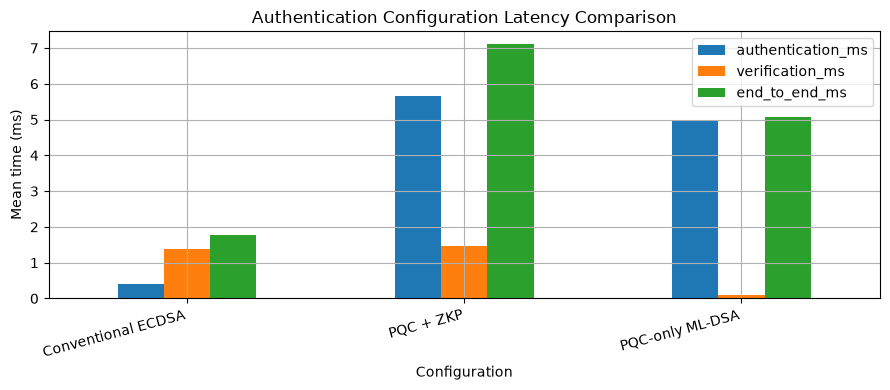

In [23]:
plot_data = ablation.set_index('configuration')[['authentication_ms', 'verification_ms', 'end_to_end_ms']]
ax = plot_data.plot(kind='bar', figsize=(9, 4), grid=True)
ax.set(title='Authentication Configuration Latency Comparison', xlabel='Configuration', ylabel='Mean time (ms)')
plt.xticks(rotation=15, ha='right'); plt.tight_layout(); plt.savefig(FIGURES_DIR / 'phase3_ablation_comparison.png', dpi=180); plt.show()

## 9. Security Validation
Each negative case is a real transaction submitted to the unmodified validator. The result table records the validator’s structured reason rather than relying on a print-only demonstration.

In [24]:
security_tests = run_security_tests()
security_tests.to_csv(RESULTS_DIR / 'security_tests.csv', index=False)
assert security_tests.passed.all(), 'a security validation case failed unexpectedly'
display(security_tests)

,test,expected_accepted,pqc_valid,zkp_valid,accepted,passed,reason
0,Valid transaction,True,True,True,True,True,Authentication and authorization successful
1,Modified transaction,False,False,False,False,True,ML-DSA signature invalid
2,Invalid signature,False,False,True,False,True,ML-DSA signature invalid
3,Wrong user,False,False,True,False,True,ML-DSA signature invalid
4,Invalid ZKP,False,True,False,False,True,Authorization proof invalid
5,Valid PQC but unauthorized user,False,True,False,False,True,Authorization proof invalid


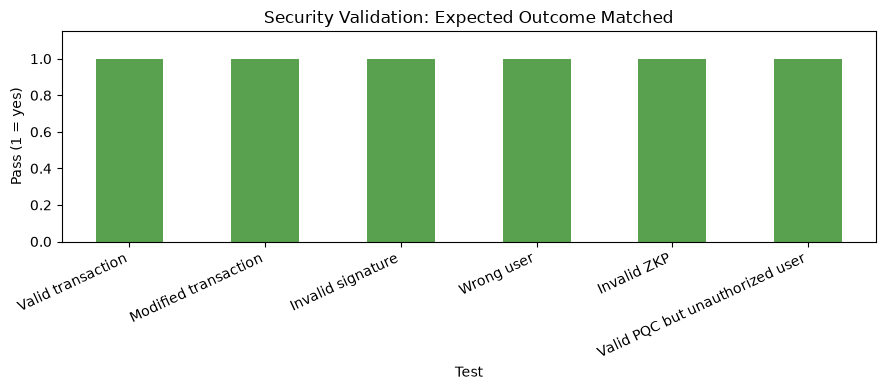

In [25]:
security_plot = security_tests.assign(result=security_tests.passed.map({True: 1, False: 0})).set_index('test')['result']
ax = security_plot.plot(kind='bar', ylim=(0, 1.15), figsize=(9, 4), color='#59A14F')
ax.set(title='Security Validation: Expected Outcome Matched', xlabel='Test', ylabel='Pass (1 = yes)')
plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.savefig(FIGURES_DIR / 'phase3_security_validation.png', dpi=180); plt.show()

## 10. Security Property Matrix
The table uses precise scope: conventional ECDSA still provides classical tamper/forgery protection; only ML-DSA configurations offer post-quantum authentication in this prototype; only the proof configuration hides the credential witness.

In [26]:
security_matrix = pd.DataFrame([
 {'Attack / Requirement':'Transaction tampering','Conventional':'ECDSA signature detects altered signed payload','PQC-only':'ML-DSA signature detects altered signed payload','PQC + ZKP':'ML-DSA and transaction-bound proof detect alteration'},
 {'Attack / Requirement':'Signature forgery','Conventional':'Classical ECDSA resistance','PQC-only':'ML-DSA resistance','PQC + ZKP':'ML-DSA resistance'},
 {'Attack / Requirement':'Quantum-resistant authentication','Conventional':'Not provided','PQC-only':'Provided by ML-DSA','PQC + ZKP':'Provided by ML-DSA'},
 {'Attack / Requirement':'Authorization privacy','Conventional':'No credential-proof layer','PQC-only':'No credential-proof layer','PQC + ZKP':'Witness remains local; proof is public'},
 {'Attack / Requirement':'Unauthorized access','Conventional':'Application policy required','PQC-only':'Application policy required','PQC + ZKP':'Unregistered credential proof rejects'}])
security_matrix.to_csv(RESULTS_DIR / 'security_property_matrix.csv', index=False)
display(security_matrix)

,Attack / Requirement,Conventional,PQC-only,PQC + ZKP
0,Transaction tampering,ECDSA signature detects altered signed payload,ML-DSA signature detects altered signed payload,ML-DSA and transaction-bound proof detect alte...
1,Signature forgery,Classical ECDSA resistance,ML-DSA resistance,ML-DSA resistance
2,Quantum-resistant authentication,Not provided,Provided by ML-DSA,Provided by ML-DSA
3,Authorization privacy,No credential-proof layer,No credential-proof layer,Witness remains local; proof is public
4,Unauthorized access,Application policy required,Application policy required,Unregistered credential proof rejects


## 11. Scalability Evaluation
Workloads process 10–1000 actual proposed transactions sequentially on one process. Total time includes signing, proof generation, validation, and insertion of accepted transactions into one block.

In [27]:
scalability = run_scalability_test()
scalability.to_csv(RESULTS_DIR / 'scalability_results.csv', index=False)
assert scalability.chain_valid.all() and (scalability.rejected_transactions == 0).all()
display(scalability.round(4))

,workload_transactions,total_processing_ms,average_latency_ms,throughput_tx_per_second,successful_transactions,rejected_transactions,memory_delta_bytes,chain_valid
0,10,70.9178,7.0918,141.0083,10,0,4096,True
1,50,356.1192,7.1224,140.4024,50,0,118784,True
2,100,710.2195,7.1022,140.8015,100,0,774144,True
3,250,1790.0219,7.1601,139.6631,250,0,-3575808,True
4,500,3571.0138,7.1420,140.0163,500,0,716800,True
5,1000,7147.8520,7.1479,139.9022,1000,0,1495040,True


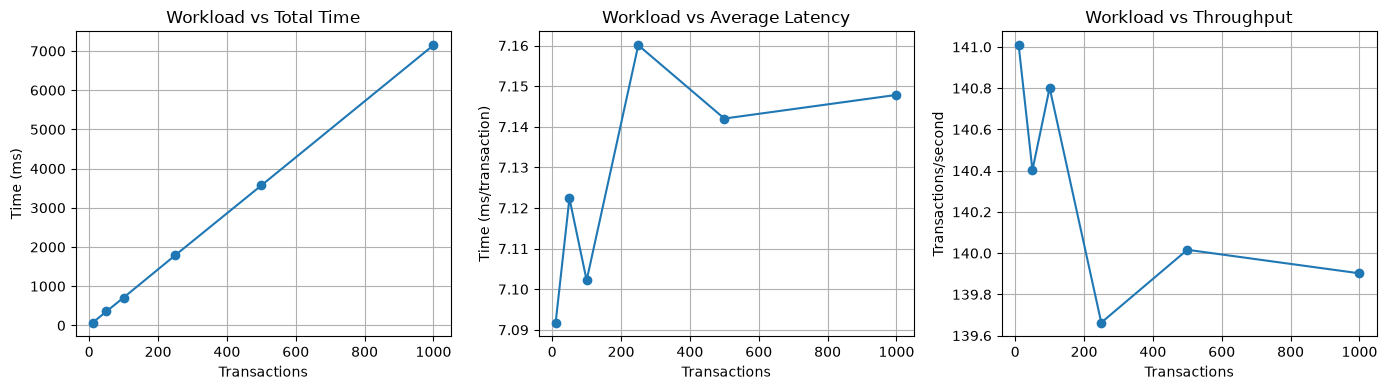

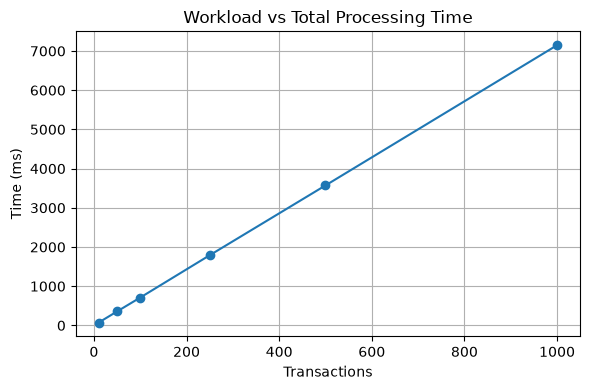

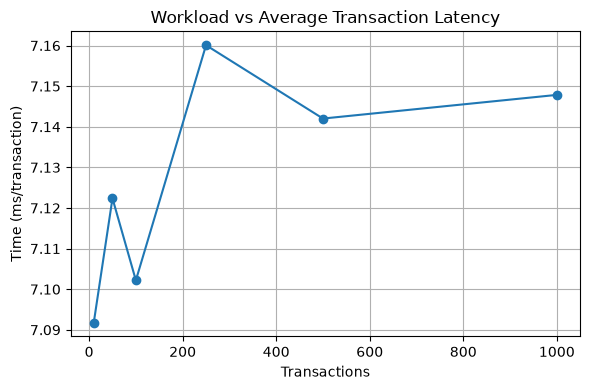

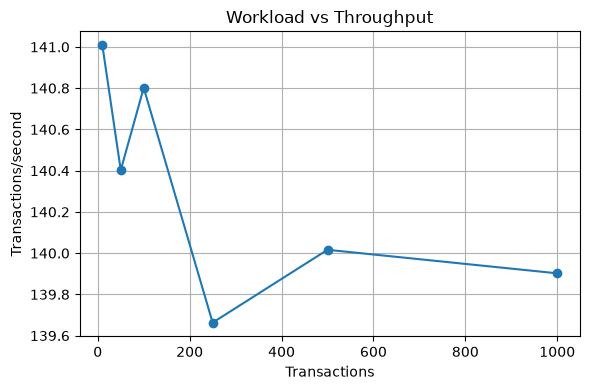

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
scalability.plot(x='workload_transactions', y='total_processing_ms', marker='o', ax=axes[0], legend=False, grid=True, title='Workload vs Total Time')
scalability.plot(x='workload_transactions', y='average_latency_ms', marker='o', ax=axes[1], legend=False, grid=True, title='Workload vs Average Latency')
scalability.plot(x='workload_transactions', y='throughput_tx_per_second', marker='o', ax=axes[2], legend=False, grid=True, title='Workload vs Throughput')
axes[0].set_ylabel('Time (ms)'); axes[1].set_ylabel('Time (ms/transaction)'); axes[2].set_ylabel('Transactions/second')
for ax in axes: ax.set_xlabel('Transactions')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'phase3_scalability.png', dpi=180); plt.show()
for metric, title, ylabel, filename in [
 ('total_processing_ms', 'Workload vs Total Processing Time', 'Time (ms)', 'phase3_workload_total_time.png'),
 ('average_latency_ms', 'Workload vs Average Transaction Latency', 'Time (ms/transaction)', 'phase3_workload_average_latency.png'),
 ('throughput_tx_per_second', 'Workload vs Throughput', 'Transactions/second', 'phase3_workload_throughput.png')]:
    ax = scalability.plot(x='workload_transactions', y=metric, marker='o', legend=False, grid=True, figsize=(6, 4))
    ax.set(title=title, xlabel='Transactions', ylabel=ylabel)
    plt.tight_layout(); plt.savefig(FIGURES_DIR / filename, dpi=180); plt.show()

## 12. Blockchain Integrity Tests
These tests mutate stored chain records and links after block hashing. They evaluate ledger integrity separately from transaction authentication.

In [29]:
integrity_tests = run_blockchain_integrity_tests()
integrity_tests.to_csv(RESULTS_DIR / 'blockchain_integrity_tests.csv', index=False)
assert integrity_tests.passed.all()
display(integrity_tests)

,test,chain_valid,expected_valid,passed
0,Valid chain,True,True,True
1,Modified transaction record,False,False,True
2,Modified block header,False,False,True
3,Broken previous-hash link,False,False,True


## 13. Results and Discussion
The following statements derive their values from this execution’s saved raw data.

In [30]:
pqc_only = ablation.loc[ablation.configuration == 'PQC-only ML-DSA', 'end_to_end_ms'].iloc[0]
proposed = ablation.loc[ablation.configuration == 'PQC + ZKP', 'end_to_end_ms'].iloc[0]
increment = (proposed - pqc_only) / pqc_only * 100
print(f'Adding ZKP authorization changed mean end-to-end latency by {increment:.1f}% relative to PQC-only in this run.')
print(f'At 1000 transactions, throughput was {scalability.iloc[-1].throughput_tx_per_second:.1f} tx/s and average latency was {scalability.iloc[-1].average_latency_ms:.3f} ms/transaction.')
print('All six security-validation cases and all four integrity cases matched their expected outcomes.')

Adding ZKP authorization changed mean end-to-end latency by 40.2% relative to PQC-only in this run.
At 1000 transactions, throughput was 139.9 tx/s and average latency was 7.148 ms/transaction.
All six security-validation cases and all four integrity cases matched their expected outcomes.


## 14. Deployment Trade-offs and 15. Limitations
ML-DSA signatures are substantially larger than conventional ECDSA signatures in this implementation; proof metadata increases transaction storage further. This prototype has no revocation, persistent secure key management, consensus, networking, anonymity, or post-quantum ZKP. Benchmark results are machine- and library-version-specific.

In [31]:
tradeoffs = pd.DataFrame([
 {'Area':'Computation','Evidence':'Measured signing, proof, verification, and workload timing in results CSVs','Deployment implication':'CPU capacity affects validation throughput'},
 {'Area':'Communication/storage','Evidence':'ML-DSA signature and serialized proof sizes recorded','Deployment implication':'Transactions carry more metadata than ECDSA-only baseline'},
 {'Area':'Key management','Evidence':'ML-DSA public/private key sizes recorded','Deployment implication':'Secure storage and lifecycle management are required'},
 {'Area':'Proof system','Evidence':'Classical secp256k1 Schnorr proof used','Deployment implication':'Authorization proof is not post-quantum'},
 {'Area':'Library maturity','Evidence':'pqcrypto binding and Python ecdsa library','Deployment implication':'Production deployment needs independent review and long-term support assessment'}])
tradeoffs.to_csv(RESULTS_DIR / 'deployment_tradeoffs.csv', index=False)
display(tradeoffs)

,Area,Evidence,Deployment implication
0,Computation,"Measured signing, proof, verification, and wor...",CPU capacity affects validation throughput
1,Communication/storage,ML-DSA signature and serialized proof sizes re...,Transactions carry more metadata than ECDSA-on...
2,Key management,ML-DSA public/private key sizes recorded,Secure storage and lifecycle management are re...
3,Proof system,Classical secp256k1 Schnorr proof used,Authorization proof is not post-quantum
4,Library maturity,pqcrypto binding and Python ecdsa library,Production deployment needs independent review...


## 16. Research Contributions and 17. Conclusion
This evaluation demonstrates a unified ML-DSA authentication and privacy-preserving authorization prototype, measures its local overhead, compares it with conventional and PQC-only configurations, validates common attack rejection, and reports workload behavior. It does not claim production readiness or novel cryptographic primitives.

# LIVE DEMONSTRATION
This one-cell workflow uses the actual PQ-ZKAuth validator. It does not reveal private ML-DSA keys or credential scalars.

In [ ]:
demo = run_demo()
print('SUCCESSFUL TRANSACTION')
print('PQC Verification:', 'VALID' if demo['valid']['pqc_valid'] else 'FAILED')
print('ZKP Verification:', 'VALID' if demo['valid']['zkp_valid'] else 'FAILED')
print('Transaction:', 'ACCEPTED' if demo['valid']['accepted'] else 'REJECTED')
print(f"Block {demo['block_index']} added; hash: {demo['block_hash']}")
print('Blockchain integrity:', 'VALID' if demo['blockchain_valid'] else 'INVALID')
print('\nATTACK 1 — TAMPERED AMOUNT')
print('PQC Verification:', 'VALID' if demo['tampered']['pqc_valid'] else 'FAILED')
print('Transaction:', 'ACCEPTED' if demo['tampered']['accepted'] else 'REJECTED')
print('\nATTACK 2 — INVALID AUTHORIZATION PROOF')
print('PQC Verification:', 'VALID' if demo['invalid_proof']['pqc_valid'] else 'FAILED')
print('ZKP Verification:', 'VALID' if demo['invalid_proof']['zkp_valid'] else 'FAILED')
print('Transaction:', 'ACCEPTED' if demo['invalid_proof']['accepted'] else 'REJECTED')
display(demo['dashboard'].replace({True: '✓', False: '✗'}))

# Phase 4 — Key Findings and Research Analysis
The findings below are calculated from existing Phase 3 CSVs, not from a new benchmark run.

In [ ]:
from pathlib import Path
phase4_results = Path('results')
ablation_final = pd.read_csv(phase4_results / 'ablation_results.csv')
scalability_final = pd.read_csv(phase4_results / 'scalability_results.csv')
security_final = pd.read_csv(phase4_results / 'security_tests.csv')
pqc_final = pd.read_csv(phase4_results / 'pqc_summary.csv')
zkp_final = pd.read_csv(phase4_results / 'zkp_summary.csv')
proposed_latency = ablation_final.loc[ablation_final.configuration == 'PQC + ZKP', 'end_to_end_ms'].iloc[0]
pqc_latency = ablation_final.loc[ablation_final.configuration == 'PQC-only ML-DSA', 'end_to_end_ms'].iloc[0]
baseline_latency = ablation_final.loc[ablation_final.configuration == 'Conventional ECDSA', 'end_to_end_ms'].iloc[0]
zkp_increment = (proposed_latency - pqc_latency) / pqc_latency * 100
baseline_overhead = (proposed_latency - baseline_latency) / baseline_latency * 100
scale_first, scale_last = scalability_final.iloc[0], scalability_final.iloc[-1]
latency_change = (scale_last.average_latency_ms - scale_first.average_latency_ms) / scale_first.average_latency_ms * 100
findings = pd.DataFrame([
 {'Finding':'PQC signing dominates local signature cost','Evidence':f"{pqc_final.loc[pqc_final.metric == 'signing_ms', 'mean_ms'].iloc[0]:.2f} ms mean vs {pqc_final.loc[pqc_final.metric == 'verification_ms', 'mean_ms'].iloc[0]:.2f} ms verification",'Interpretation':'Signing is the largest isolated ML-DSA operation in this implementation.'},
 {'Finding':'Proof authorization has measurable cost','Evidence':f"{zkp_final.loc[zkp_final.metric == 'proof_generation_ms', 'mean_ms'].iloc[0]:.3f} ms generation; {zkp_final.loc[zkp_final.metric == 'proof_verification_ms', 'mean_ms'].iloc[0]:.3f} ms verification",'Interpretation':'Privacy-preserving authorization adds computation beyond signature-only validation.'},
 {'Finding':'ZKP increases PQC-only latency','Evidence':f"{pqc_latency:.2f} to {proposed_latency:.2f} ms ({zkp_increment:.1f}%)",'Interpretation':'The ablation isolates the local incremental cost of the proof layer.'},
 {'Finding':'PQC+ZKP exceeds local conventional baseline','Evidence':f"{baseline_latency:.2f} to {proposed_latency:.2f} ms ({baseline_overhead:.1f}%)",'Interpretation':'The added security and privacy properties come with measured local overhead.'},
 {'Finding':'Workload throughput is stable in tested range','Evidence':f"{scale_first.throughput_tx_per_second:.1f}–{scale_last.throughput_tx_per_second:.1f} tx/s; latency change {latency_change:.2f}%",'Interpretation':'Sequential processing was approximately linear from 10 to 1,000 transactions.'},
 {'Finding':'Attack checks behaved as designed','Evidence':f"{int(security_final.passed.sum())}/{len(security_final)} validator cases matched expected outcomes",'Interpretation':'The tested malformed, tampered, forged, and unauthorized inputs were rejected.'}])
display(findings)

## Security Findings and Trade-off Summary
The validator tests establish correct behavior for the tested inputs, not a general security proof. ML-DSA protects the signed transaction fields; the proof protects the credential witness from direct disclosure. Costs include ML-DSA signature size, proof metadata, local computation, and key/credential management complexity. The classical secp256k1 proof is not post-quantum and remains the primary cryptographic limitation.

In [ ]:
security_dashboard = security_final.assign(
    PQC=security_final.pqc_valid.map({True: '✓', False: '✗'}),
    ZKP=security_final.zkp_valid.map({True: '✓', False: '✗'}),
    Result=security_final.accepted.map({True: 'ACCEPT', False: 'REJECT'}))
display(security_dashboard[['test', 'PQC', 'ZKP', 'Result', 'reason']])

# Phase 6 — IEEE Readiness
`docs/ieee_paper_outline.md` contains the paper-ready abstract, architecture, algorithms, methodology, six results tables, discussion, limitations, future work, and a preliminary reference list. The notebook and CSV files remain the authoritative source for every reported measurement.